# Лекция 7. Численное дифференцирование на комплексной плоскости (комплексный шаг)

Как посчитать первую производную с точностью до машинного эпсилон, взяв исчезающе малый шаг — и почему обычные разности так не умеют.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 110
print('numpy', np.__version__)

numpy 2.5.4


## 1. 🎯 Постановка задачи

Из прошлой лекции помним дилемму обычных разностей. Для формулы вперёд
$$
f'(x) \approx \frac{f(x+h) - f(x)}{h}
$$
полная ошибка — это сумма двух слагаемых с противоположным поведением:
$$
\text{ошибка} \le \frac{2\delta}{h} + \frac{M_2}{2} h,
$$
где $\delta$ — погрешность вычисления значений функции, $M_2 = \max|f''|$.
Первое слагаемое — вычислительный шум: при $h \to 0$ числитель $f(x+h)-f(x)$
состоит из почти равных чисел, значащие цифры сокращаются (катастрофическое
сокращение), а деление на крошечное $h$ раздувает остатки. Второе — ошибка
аппроксимации, она, наоборот, падает с уменьшением $h$.

Итог — $U$-кривая: есть оптимальный шаг $h_{opt} \sim \sqrt{\delta}$,
меньше которого брать нельзя. Точность упирается в потолок $\sim \sqrt{\delta}$
и никогда не достигает машинной.

> ❓ **Вопрос лекции:** можно ли избавиться от вычитания близких чисел вовсе —
и тогда брать сколь угодно малый шаг без роста шума?

## 2. 💡 Идея: шагнуть не вдоль оси, а вверх

Все классические формулы шевелят точку **вдоль вещественной оси**: $x+h$, $x-h$.
А что, если шевельнуть её **в мнимом направлении** — рассмотреть $f(x + ih)$?

Комплексное число хранится как **два независимых** вещественных числа
$(\text{Re}, \text{Im})$. Малая мнимая добавка $ih$ не складывается с $x$
в одном регистре и не округляется до $x$ — она живёт в своей компоненте.
Поэтому информацию о наклоне функции можно прочитать из мнимой части
**без вычитания** двух близких чисел.

Цена: функция должна уметь принимать комплексный аргумент и быть
аналитической (гладко продолжаться в комплексную плоскость).

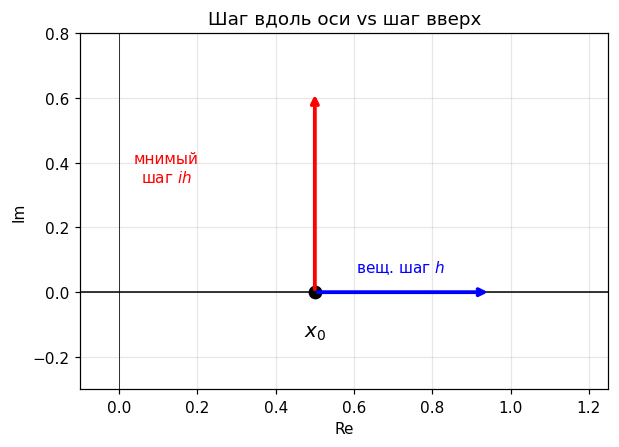

In [2]:
# Геометрия идеи: вещественный шаг идёт по оси (там вычитание),
# мнимый — перпендикулярно ей (вычитания нет)
fig, ax = plt.subplots(figsize=(6.2, 4.2))
ax.axhline(0, color='k', lw=1)
ax.axvline(0, color='k', lw=0.5)
ax.plot(0.5, 0, 'ko', ms=8)
ax.text(0.5, -0.14, '$x_0$', ha='center', fontsize=13)
ax.annotate('', xy=(0.95, 0), xytext=(0.5, 0),
            arrowprops=dict(arrowstyle='->', color='blue', lw=2.5))
ax.text(0.72, 0.06, 'вещ. шаг $h$', color='blue', ha='center')
ax.annotate('', xy=(0.5, 0.62), xytext=(0.5, 0),
            arrowprops=dict(arrowstyle='->', color='red', lw=2.5))
ax.text(0.12, 0.34, 'мнимый\nшаг $ih$', color='red', ha='center')
ax.set_xlim(-0.1, 1.25); ax.set_ylim(-0.3, 0.8)
ax.set_xlabel('Re'); ax.set_ylabel('Im')
ax.set_title('Шаг вдоль оси vs шаг вверх')
ax.grid(True, alpha=0.3)
plt.show()

## 3. 📐 Вывод формулы

Пусть $f$ вещественна на вещественной оси и аналитична. Разложим её в ряд Тейлора
в точке $x$ с чисто мнимым приращением $ih$:
$$
f(x + ih) = f(x) + ihf'(x) - \frac{h^2}{2}f''(x) - i\frac{h^3}{6}f'''(x) + \dots
$$
Вещественные и мнимые слагаемые здесь чередуются. Берём мнимую часть обеих сторон
и делим на $h$:
$$
f'(x) = \frac{\mathrm{Im}\, f(x + ih)}{h} + \frac{h^2}{6}f'''(x) + \dots
$$
Отбрасывая остаток, получаем формулу комплексного шага:
$$
f'(x) \approx \frac{\mathrm{Im}\, f(x + ih)}{h}
$$
Порядок точности — второй, $O(h^2)$, как у центральной разности. Но в формуле
**нет вычитания**: мнимая часть читается напрямую.

> 🧠 Для контроля: вещественная часть того же разложения даёт
$\mathrm{Re}\, f(x+ih) = f(x) - h^2 f''(x)/2 + \dots$,
то есть значение самой функции с точностью $O(h^2)$ — бесплатно, из той же
одной комплексной оценки.

## 4. 🔬 Почему исчезает шум округления

Сравним в лоб, что происходит во float-арифметике при крошечном $h$.

**Обычная разность.** Пусть для наглядности $f(x) = 1 + x$ вблизи нуля.
При $h$ меньше машинного эпсилон $1 + h$ округляется ровно до $1$,
числитель $f(h) - f(0)$ становится нулём — производная «умирает».
При чуть больших $h$ числитель — разность почти равных чисел:
из 16 значащих цифр остаётся несколько, деление на $h$ усиливает мусор.
Отсюда слагаемое $\delta/h$ в оценке ошибки.

**Комплексный шаг.** Та же функция: $f(ih) = 1 + ih$ представимо **точно** —
единица сидит в вещественной компоненте, $h$ — в мнимой, они не смешиваются.
$\mathrm{Im}\, f(ih)/h = h/h = 1$ — точный ответ при любом $h$,
вплоть до $10^{-200}$ (далеко above границы $10^{-308}$ типа double).

Математически: ошибка формулы — только $O(h^2)$, слагаемого $\delta/h$
нет в принципе. Уменьшая $h$, мы давим ошибку аппроксимации —
а ошибка округления не растёт. $U$-кривая превращается в плоскую линию
на уровне машинной точности.

точная f'(0.5) = 1.648721270700128

       h |    вперёд | центральная | компл. шаг
   1e-01 |  8.53e-02 |  2.75e-03 |  2.75e-03
   1e-04 |  8.24e-05 |  2.75e-09 |  2.75e-09
   1e-08 |  2.21e-08 |  1.10e-08 |  2.22e-16
   1e-12 |  4.01e-05 |  4.01e-05 |  0.00e+00
   1e-20 |  1.65e+00 |  1.65e+00 |  2.22e-16
  1e-100 |  1.65e+00 |  1.65e+00 |  0.00e+00
  1e-200 |  1.65e+00 |  1.65e+00 |  0.00e+00


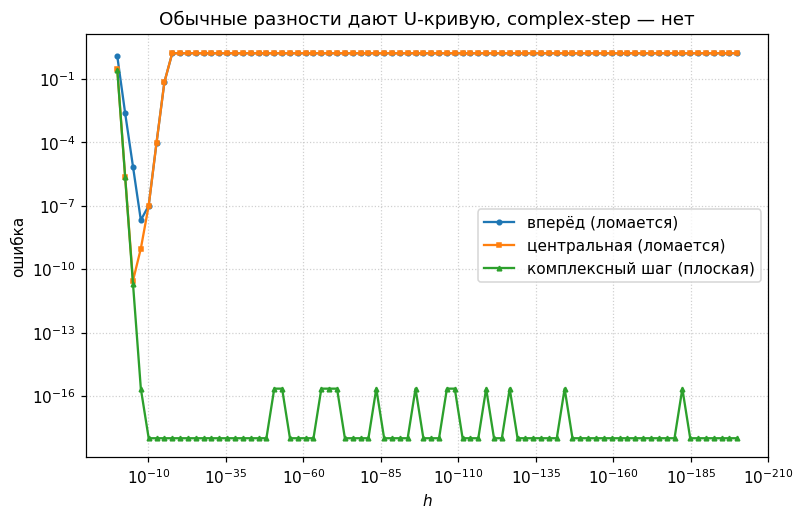

In [3]:
# Главный эксперимент: U-кривые обычных разностей vs плоская линия complex-step
# f(x)=exp(x), x0=0.5; h от 1 до 1e-200
f = lambda x: np.exp(x)
x0, exact = 0.5, np.exp(0.5)
hs = np.logspace(0, -200, 80)
err_fw, err_ce, err_cs = [], [], []
for h in hs:
    err_fw.append(abs((f(x0 + h) - f(x0)) / h - exact))
    err_ce.append(abs((f(x0 + h) - f(x0 - h)) / (2 * h) - exact))
    err_cs.append(abs(np.imag(f(x0 + 1j * h)) / h - exact))
floor = 1e-18
err_fw = np.maximum(err_fw, floor); err_ce = np.maximum(err_ce, floor); err_cs = np.maximum(err_cs, floor)

print(f"точная f'({x0}) = {exact:.15f}\n")
print(f"{'h':>8} | {'вперёд':>9} | {'центральная':>9} | {'компл. шаг':>9}")
for h in [1e-1, 1e-4, 1e-8, 1e-12, 1e-20, 1e-100, 1e-200]:
    fw = abs((f(x0 + h) - f(x0)) / h - exact)
    ce = abs((f(x0 + h) - f(x0 - h)) / (2 * h) - exact)
    cs = abs(np.imag(f(x0 + 1j * h)) / h - exact)
    print(f"{h:8.0e} | {fw:9.2e} | {ce:9.2e} | {cs:9.2e}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(hs, err_fw, 'o-', ms=3, label='вперёд (ломается)')
ax.loglog(hs, err_ce, 's-', ms=3, label='центральная (ломается)')
ax.loglog(hs, err_cs, '^-', ms=3, label='комплексный шаг (плоская)')
ax.set_xlabel('$h$'); ax.set_ylabel('ошибка')
ax.grid(True, which='both', linestyle=':', alpha=0.6)
ax.legend(); ax.invert_xaxis()
ax.set_title('Обычные разности дают U-кривую, complex-step — нет')
plt.show()

## 5. 📉 Проверка порядка: при умеренных шагах формулы совпадают

Комплексный шаг — метод второго порядка, как центральная разность.
При умеренных $h$ (когда шум округления ещё не вмешивается) их ошибки
практически равны: главные члены остатков совпадают по величине.
Делением шага пополам убеждаемся: ошибка падает в 4 раза — порядок $O(h^2)$. 🐇

In [4]:
# Порядок — второй: ошибка /4 при h/2. При h=1e-2..1e-4 complex-step и центральная идут ноздря в ноздрю.
g, x0 = lambda x: np.sin(x), 1.0
exact = np.cos(x0)
print(f"{'h':>8} | {'компл. шаг':>10} {'err':>9} | {'центр.':>10} {'err':>9} | падение")
prev = None
for h in [0.2, 0.1, 0.05, 0.025]:
    cs = np.imag(g(x0 + 1j * h)) / h
    ce = (g(x0 + h) - g(x0 - h)) / (2 * h)
    ec, ee = abs(cs - exact), abs(ce - exact)
    ratio = f"{prev / ec:5.2f}x" if prev else "  --  "
    print(f"{h:8.3f} | {cs:10.7f} {ec:9.2e} | {ce:10.7f} {ee:9.2e} | {ratio}")
    prev = ec
print("\nПадение ~4x при делении шага вдвое — второй порядок. А при h=1e-8 complex-step уже точен до эпсилон.")
print(f"h=1e-8:  complex-step err={abs(np.imag(g(x0 + 1j*1e-8)) / 1e-8 - exact):.2e}, "
      f"центральная err={abs((g(x0 + 1e-8) - g(x0 - 1e-8)) / 2e-8 - exact):.2e}")

       h | компл. шаг       err |     центр.       err | падение
   0.200 |  0.5439115  3.61e-03 |  0.5367075  3.59e-03 |   --  
   0.100 |  0.5412033  9.01e-04 |  0.5394023  9.00e-04 |  4.01x
   0.050 |  0.5405275  2.25e-04 |  0.5400772  2.25e-04 |  4.00x
   0.025 |  0.5403586  5.63e-05 |  0.5402460  5.63e-05 |  4.00x

Падение ~4x при делении шага вдвое — второй порядок. А при h=1e-8 complex-step уже точен до эпсилон.
h=1e-8:  complex-step err=0.00e+00, центральная err=2.58e-09


## 6. ⚠️ Границы применимости

Метод не волшебный. Три честных ограничения:

**1. Аналитичность.** Формула держится на ряде Тейлора в комплексной окрестности.
Функции с изломом ($|x|$, $\max$, ветвления `if x > 0`) не продолжаются аналитически —
результат будет мусором. Ниже — пример: $|x|$ в нуле даёт $0$ вместо несуществующей
производной. Общее правило: если код ветвится по знаку вещественного значения,
комплексная оценка пройдёт не по той ветке.

**2. Вторая производная — снова с вычитанием.** Из вещественной части разложения:
$$
f''(x) \approx \frac{2\,(f(x) - \mathrm{Re}\, f(x + ih))}{h^2}
$$
Здесь вычитание вернулось — при малых $h$ снова $U$-кривая и оптимальный шаг.
Для старших производных без вычитания нужны многокомплексные и гипер-дуальные числа
(коротко — в следующем разделе).

**3. Комплексная арифметика в коде.** Функция обязана принимать комплексный аргумент:
все операции внутри должны поддерживать `complex` (в `numpy` — обычно да).
Цена одной оценки — примерно двойная (вещественная + мнимая части), зато оценка одна —
против двух у центральной разности.

complex-step для |x| в x=0: 0.0  (а производной там не существует!)
Вывод: метод только для аналитических функций.



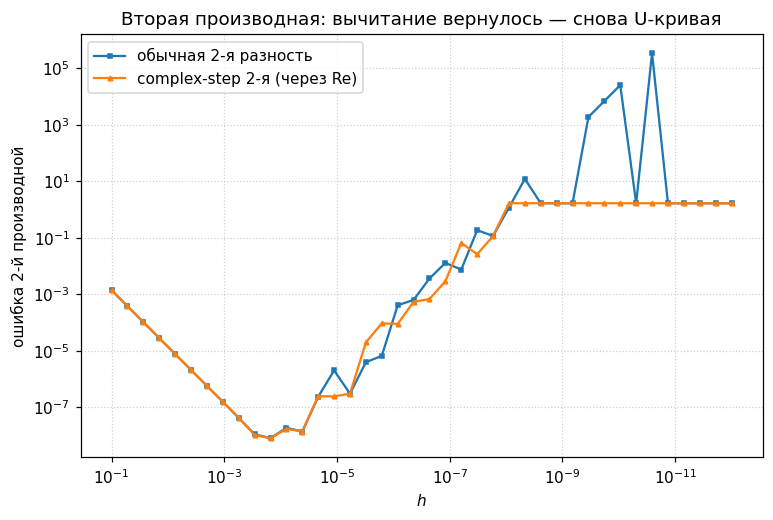

In [5]:
# Ограничение 1: неаналитическая функция ломается. |x| в нуле: производной нет, complex-step врёт уверенно.
h = 1e-20
v = np.imag(np.abs(0.0 + 1j * h)) / h
print(f"complex-step для |x| в x=0: {v}  (а производной там не существует!)")
print("Вывод: метод только для аналитических функций.\n")

# Ограничение 2: вторая производная через Re — снова U-кривая (вычитание вернулось)
f = lambda x: np.exp(x)
x0, exact2 = 0.5, np.exp(0.5)
hs2 = np.logspace(-1, -12, 40)
e_cs2, e_st2 = [], []
for h in hs2:
    e_cs2.append(abs(2 * (f(x0) - np.real(f(x0 + 1j * h))) / h ** 2 - exact2))
    e_st2.append(abs((f(x0 - h) - 2 * f(x0) + f(x0 + h)) / h ** 2 - exact2))
e_cs2 = np.maximum(e_cs2, 1e-18); e_st2 = np.maximum(e_st2, 1e-18)
fig, ax = plt.subplots(figsize=(8, 5))
ax.loglog(hs2, e_st2, 's-', ms=3, label='обычная 2-я разность')
ax.loglog(hs2, e_cs2, '^-', ms=3, label='complex-step 2-я (через Re)')
ax.set_xlabel('$h$'); ax.set_ylabel('ошибка 2-й производной')
ax.grid(True, which='both', linestyle=':', alpha=0.6)
ax.legend(); ax.invert_xaxis()
ax.set_title('Вторая производная: вычитание вернулось — снова U-кривая')
plt.show()

## 7. 🛠️ Куда это идёт: старшие производные и связь с автодифференцированием

Идея «шагнуть в не-вещественном направлении и прочитать ответ из добавочной компоненты
без вычитания» обобщается:

- **Многокомплексные числа** — несколько независимых мнимых осей: $n$-я производная
читается из компоненты $h^n$, вычитания нет, шаг можно давить до машинной точности.
- **Гипер-дуальные числа** — оси с нильпотентным правилом ($\varepsilon^2 = 0$ вместо $i^2 = -1$):
ряд Тейлора обрывается ровно на нужном члене, производные получаются **точными**
(нет даже ошибки $O(h^2)$), а не приближёнными.

> 🧠 **Мостик к следующей лекции:** автодифференцирование — это та же философия,
доведённая до предела: вместо конечного (пусть и крошечного) шага — точное правило
дифференцирования для каждой элементарной операции, применённое по графу вычислений.
Комплексный шаг — отличный способ **проверять** реализации автодифференцирования:
эталон с точностью до эпсилон одной строкой кода.